# XLM-R Fine-tuning retrieval across Romansh idioms

Set `DATA_DIR` to the folder containing `train.jsonl`, `valid.jsonl` and `test.jsonl`, then run the cells in order. Works in Colab and local Jupyter kernels, including VS Code. This notebook always trains a new model; use a GPU if available.

Dependencies: torch, transformers, sentencepiece, numpy, pandas, scikit-learn, matplotlib, tqdm and IPython. Install them in the selected Python environment before running. Results from a previous notebook are not included.


## 1. Imports

In [4]:
from pathlib import Path
from itertools import combinations
from collections import Counter
import html
import json
import random
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
from IPython.display import display

## 2. Configuration

In [5]:
# Detect Google Colab
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Recommended project structure:
# Zero-Shot_Semantic_Retrieval/
# ├── data/
# │   ├── train.jsonl
# │   ├── valid.jsonl
# │   └── test.jsonl
# └── notebooks/
#     └── mediomatix_finetuning_simple.ipynb
#
# In Colab, the dataset files will be uploaded automatically.
# In VS Code, run the notebook from the notebooks/ directory,
# so ../data points to the dataset folder.

if IN_COLAB:
    DATA_DIR = Path('/content/data')
else:
    DATA_DIR = Path('../data')


OUTPUT_DIR = Path('outputs/xlm-r-simple')
MODEL_NAME = 'FacebookAI/xlm-roberta-base'
SEED = 42
EVAL_SEED = 13
EPOCHS = 4
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
TEMPERATURE = 0.05
MAX_LENGTH = 128
PATIENCE = 2
EVAL_MAX_ROWS = 0  # Full test. Set 500 for a smaller candidate-pool experiment.
ENCODE_BATCH_SIZE = 32
RANK_BATCH_SIZE = 128
IDIOMS = ['rm-sursilv', 'rm-sutsilv', 'rm-surmiran', 'rm-puter', 'rm-vallader']
IDIOM_PAIRS = list(combinations(IDIOMS, 2))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#For reprodicibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)
print('Device:', DEVICE)
if DEVICE.type == 'cpu':
    print('Training XLM-R on CPU can take a long time. A GPU is recommended.') #it can really take a long time with cpu (COLAB OFFERS FREE GPU SESSIONS)

Device: cuda


## 3. Load and prepare the data

In [6]:
# Upload dataset files in Google Colab
if IN_COLAB:
    from google.colab import files

    DATA_DIR.mkdir(parents=True, exist_ok=True)

    required_files = ['train.jsonl', 'valid.jsonl', 'test.jsonl']
    missing = [f for f in required_files if not (DATA_DIR / f).exists()]

    if missing:
        print('Upload:', ', '.join(missing))
        uploaded = files.upload()

        for filename, content in uploaded.items():
            (DATA_DIR / filename).write_bytes(content)


# Clean text
def clean_text(value):
    if not isinstance(value, str):
        return ''
    text = html.unescape(value)
    text = re.sub(r'<[^>]*>', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()


# Load datasets
frames = {}

for split, filename in [
    ('train', 'train.jsonl'),
    ('validation', 'valid.jsonl'),
    ('test', 'test.jsonl')
]:
    path = DATA_DIR / filename

    if not path.is_file():
        raise FileNotFoundError(f'Missing file: {path}')

    frame = pd.read_json(path, lines=True).reset_index(drop=True)

    for idiom in IDIOMS:
        frame[idiom] = frame[idiom].map(clean_text)

    frames[split] = frame
    print(split, len(frame), 'aligned rows')


# Check shared books
for left, right in combinations(frames, 2):
    if all('book' in frames[s] for s in (left, right)):
        shared = set(frames[left]['book']) & set(frames[right]['book'])
        print(f'{left}/{right}: {len(shared)} shared book IDs')

Upload: train.jsonl, valid.jsonl, test.jsonl


Saving test.jsonl to test.jsonl
Saving train.jsonl to train.jsonl
Saving valid.jsonl to valid.jsonl
train 12382 aligned rows
validation 7507 aligned rows
test 4858 aligned rows
train/validation: 0 shared book IDs
train/test: 0 shared book IDs
validation/test: 0 shared book IDs


## 4. Training pairs

Sample one available idiom pair from each aligned row per epoch. Inverse-frequency weights reduce pair imbalance.

In [7]:
train_options = []
for row in frames['train'].itertuples(index=False, name=None):
    values = dict(zip(frames['train'].columns, row))
    options = [(a, b, values[a], values[b]) for a, b in IDIOM_PAIRS if values[a] and values[b]]
    if options:
        train_options.append(options)
pair_counts = Counter((a, b) for options in train_options for a, b, _, _ in options)

def sample_training_pairs(epoch):
    rng = random.Random(SEED + epoch)
    examples = []
    for options in train_options:
        weights = [1 / pair_counts[(a, b)] for a, b, _, _ in options]
        examples.append(rng.choices(options, weights=weights, k=1)[0])
    rng.shuffle(examples)
    return examples

print('Training examples per epoch:', len(train_options))

Training examples per epoch: 12382


## 5. Tokenizer and embeddings

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def embed_texts(model, texts):
    tokens = tokenizer(texts, padding=True, truncation=True,
                       max_length=MAX_LENGTH, return_tensors='pt').to(DEVICE)
    hidden = model(**tokens).last_hidden_state
    mask = tokens['attention_mask'].unsqueeze(-1).to(hidden.dtype)
    pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
    return F.normalize(pooled, p=2, dim=1)

@torch.inference_mode()
def encode_rows(model, frame, selected):
    model.eval()
    vectors = {}
    for idiom in IDIOMS:
        ids = sorted(selected[idiom])
        vectors[idiom] = {}
        for start in tqdm(range(0, len(ids), ENCODE_BATCH_SIZE), desc=idiom):
            batch_ids = ids[start:start + ENCODE_BATCH_SIZE]
            texts = frame.loc[batch_ids, idiom].tolist()
            batch_vectors = embed_texts(model, texts).cpu().numpy()
            vectors[idiom].update(zip(batch_ids, batch_vectors))
    return vectors

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

## 6. Retrieval metrics

The final comparison uses the character-overlap buckets, sampling and optimistic tie rule from `retrieval_pipeline_implementation`. Low-overlap queries keep the same candidate pool.

In [9]:
SPACE_RE = re.compile(r'\s+')


In [10]:
def char_ngrams(text, min_n=3, max_n=5):
    text = SPACE_RE.sub(' ', text.lower()).strip()
    if not text:
        return set()
    padded = f' {text} '
    grams = set()
    for n in range(min_n, max_n + 1):
        if len(padded) < n:
            grams.add(padded)
            continue
        grams.update((padded[i:i + n] for i in range(len(padded) - n + 1)))
    return grams

In [11]:
def jaccard(left, right, min_n=3, max_n=5):
    left_grams = char_ngrams(left, min_n=min_n, max_n=max_n)
    right_grams = char_ngrams(right, min_n=min_n, max_n=max_n)
    if not left_grams and (not right_grams):
        return 0.0
    overlap = left_grams & right_grams
    union = left_grams | right_grams
    return len(overlap) / len(union)

In [12]:
def add_overlap_buckets(pairs, low_q=0.33, high_q=0.67):
    if pairs.empty:
        out = pairs.copy()
        out['overlap'] = []
        out['bucket'] = []
        return (out, {'low_max': 0.0, 'high_min': 0.0})
    out = pairs.copy()
    out['overlap'] = [jaccard(src, tgt) for src, tgt in zip(out['src_text'], out['tgt_text'])]
    values = out['overlap'].to_numpy()
    low_max = float(np.quantile(values, low_q))
    high_min = float(np.quantile(values, high_q))
    out['bucket'] = 'mid'
    out.loc[out['overlap'] <= low_max, 'bucket'] = 'low'
    out.loc[out['overlap'] >= high_min, 'bucket'] = 'high'
    return (out, {'low_max': low_max, 'high_min': high_min})

In [13]:
def summarize_ranks(ranks):
    values = np.asarray(list(ranks), dtype=float)
    if values.size == 0:
        return {'n': 0, 'recall_at_1': 0.0, 'mrr': 0.0, 'mean_rank': 0.0}
    return {'n': int(values.size), 'recall_at_1': float(np.mean(values == 1)), 'mrr': float(np.mean(1.0 / values)), 'mean_rank': float(np.mean(values))}

In [14]:
def summarize_by_bucket(ranks, buckets):
    rank_values = np.asarray(list(ranks), dtype=int)
    bucket_values = np.asarray(list(buckets), dtype=object)
    rows = [{'bucket': 'all', **summarize_ranks(rank_values)}]
    for bucket in ('low', 'mid', 'high'):
        mask = bucket_values == bucket
        rows.append({'bucket': bucket, **summarize_ranks(rank_values[mask])})
    return rows

In [15]:
def ranks_from_vectors(query_vecs, cand_vecs, gold, batch_size=128):
    gold = np.asarray(gold, dtype=int)
    ranks = np.empty(len(gold), dtype=int)
    for start in range(0, len(gold), batch_size):
        stop = min(start + batch_size, len(gold))
        scores = query_vecs[start:stop] @ cand_vecs.T
        if hasattr(scores, 'toarray'):
            scores = scores.toarray()
        scores = np.asarray(scores)
        for offset, row in enumerate(scores):
            gold_score = row[gold[start + offset]]
            ranks[start + offset] = int(np.sum(row > gold_score) + 1)
    return ranks

In [16]:
def tfidf_vectors(queries, candidates, min_n=3, max_n=5):
    vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(min_n, max_n), lowercase=True, strip_accents=None)
    vec.fit(list(queries) + list(candidates))
    query_vecs = normalize(vec.transform(queries))
    cand_vecs = normalize(vec.transform(candidates))
    return (query_vecs, cand_vecs)

## 7. Build evaluation pairs

In [17]:
def build_evaluation(frame, max_rows=0):
    pairs = {}
    selected = {idiom: set() for idiom in IDIOMS}
    for a, b in IDIOM_PAIRS:
        valid = frame.loc[frame[a].ne('') & frame[b].ne(''), [a, b]]
        if max_rows and len(valid) > max_rows:
            valid = valid.sample(n=max_rows, random_state=EVAL_SEED).sort_index()
        if valid.empty:
            raise ValueError(f'No aligned examples for {a}/{b}')
        ids = valid.index.to_numpy()
        p = pd.DataFrame({'src_text': valid[a].tolist(), 'tgt_text': valid[b].tolist()})
        p['gold'] = np.arange(len(p))
        p, thresholds = add_overlap_buckets(p)
        pairs[(a, b)] = (p, ids, thresholds)
        selected[a].update(ids)
        selected[b].update(ids)
    return pairs, selected

valid_pairs, valid_rows = build_evaluation(frames['validation'])
test_pairs, test_rows = build_evaluation(frames['test'], EVAL_MAX_ROWS)
print('Test segments to encode per model:', sum(map(len, test_rows.values())))

Test segments to encode per model: 23219


## 8. Evaluate a model

In [18]:
def evaluate_retrieval(label, pairs, vectors=None):
    results = []
    for (a, b), (p, ids, thresholds) in tqdm(pairs.items(), desc=label):
        if vectors is None:
            left, right = tfidf_vectors(p.src_text.tolist(), p.tgt_text.tolist())
        else:
            left = np.stack([vectors[a][i] for i in ids])
            right = np.stack([vectors[b][i] for i in ids])
        for src, tgt, queries, candidates in [(a, b, left, right), (b, a, right, left)]:
            ranks = ranks_from_vectors(queries, candidates, p.gold.to_numpy(), RANK_BATCH_SIZE)
            for scores in summarize_by_bucket(ranks, p.bucket.tolist()):
                results.append({'model': label, 'src': src, 'tgt': tgt, **thresholds, **scores})
    return pd.DataFrame(results)

def macro_summary(report):
    return report.groupby(['model', 'bucket'], as_index=False).agg(
        directions=('src', 'count'), queries=('n', 'sum'),
        recall_at_1=('recall_at_1', 'mean'), mrr=('mrr', 'mean'))

## 9. Model selection

Compare multilingual encoders on the validation set before fine-tuning.

In [25]:
# Compare multilingual models on validation data
CANDIDATE_MODELS = {
    'mBERT': 'google-bert/bert-base-multilingual-cased',
    'XLM-R': 'FacebookAI/xlm-roberta-base',
    'MiniLM': 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
}

comparison_results = []

for name, model_id in CANDIDATE_MODELS.items():
    print(f'Evaluating {name}...')

    tokenizer = AutoTokenizer.from_pretrained(model_id)
    candidate_model = AutoModel.from_pretrained(model_id).to(DEVICE)

    vectors = encode_rows(candidate_model, frames['validation'], valid_rows)
    results = evaluate_retrieval(name, valid_pairs, vectors)

    summary = macro_summary(results)
    overall = summary[summary['bucket'] == 'all'].iloc[0]

    comparison_results.append({
        'Model': name,
        'Recall@1': overall['recall_at_1'],
        'MRR': overall['mrr']
    })

    del candidate_model, vectors
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.sort_values('MRR', ascending=False).round(4))

# Restore the tokenizer used for XLM-R training
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

Evaluating mBERT...


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

... (30 outputs left out)

rm-puter:   0%|          | 0/230 [00:00<?, ?it/s]

rm-vallader:   0%|          | 0/231 [00:00<?, ?it/s]

MiniLM:   0%|          | 0/10 [00:00<?, ?it/s]

,Model,Recall@1,MRR
0,mBERT,0.5417,0.6103
2,MiniLM,0.4182,0.4826
1,XLM-R,0.3646,0.4174


mBERT achieved the best zero-shot results, while XLM-R performed the worst. We decided to focus on XLM-R to investigate whether a model with relatively poor initial performance could still achieve good results through task-specific fine-tuning, especially on segments with low lexical overlap.

## 10. Zero-shot test baseline

In [19]:
model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
zero_vectors = encode_rows(model, frames['test'], test_rows)
zero_report = evaluate_retrieval('XLM-R zero-shot', test_pairs, zero_vectors)
del zero_vectors
display(macro_summary(zero_report).round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


rm-sursilv:   0%|          | 0/149 [00:00<?, ?it/s]

rm-sutsilv:   0%|          | 0/149 [00:00<?, ?it/s]

rm-surmiran:   0%|          | 0/137 [00:00<?, ?it/s]

rm-puter:   0%|          | 0/146 [00:00<?, ?it/s]

rm-vallader:   0%|          | 0/147 [00:00<?, ?it/s]

XLM-R zero-shot:   0%|          | 0/10 [00:00<?, ?it/s]

,model,bucket,directions,queries,recall_at_1,mrr
0,XLM-R zero-shot,all,20,89684,0.3992,0.4505
1,XLM-R zero-shot,high,20,29664,0.7120,0.7593
2,XLM-R zero-shot,low,20,29654,0.1378,0.1796
3,XLM-R zero-shot,mid,20,30366,0.3488,0.4135


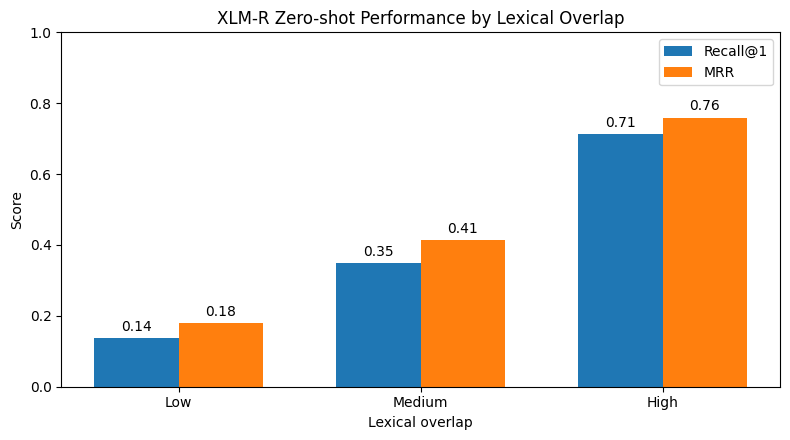

In [26]:
# Zero-shot results by lexical overlap
results = macro_summary(zero_report)
results = results[results['bucket'].isin(['low', 'mid', 'high'])]

results = results.set_index('bucket').loc[['low', 'mid', 'high']]

x = np.arange(len(results))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))

bars1 = ax.bar(
    x - width / 2,
    results['recall_at_1'],
    width,
    label='Recall@1'
)

bars2 = ax.bar(
    x + width / 2,
    results['mrr'],
    width,
    label='MRR'
)

ax.set_xticks(x)
ax.set_xticklabels(['Low', 'Medium', 'High'])
ax.set_xlabel('Lexical overlap')
ax.set_ylabel('Score')
ax.set_title('XLM-R Zero-shot Performance by Lexical Overlap')
ax.set_ylim(0, 1)
ax.legend()

for bars in [bars1, bars2]:
    ax.bar_label(bars, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

## 11. Fine-tuning

Use symmetric in-batch contrastive loss. Select the checkpoint with the highest validation macro MRR; test scores are not used for selection.

In [20]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
training_log = []
best_mrr = -float('inf')
best_state = None
stale_epochs = 0

for epoch in range(EPOCHS):
    examples = sample_training_pairs(epoch)
    model.train()
    losses = []
    started = time.perf_counter()
    for start in tqdm(range(0, len(examples), BATCH_SIZE), desc=f'Epoch {epoch + 1}'):
        batch = examples[start:start + BATCH_SIZE]
        if len(batch) < 2:
            continue
        left = embed_texts(model, [item[2] for item in batch])
        right = embed_texts(model, [item[3] for item in batch])
        scores = left @ right.T / TEMPERATURE
        labels = torch.arange(len(batch), device=DEVICE)
        loss = (F.cross_entropy(scores, labels) + F.cross_entropy(scores.T, labels)) / 2
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.detach().item())

    valid_vectors = encode_rows(model, frames['validation'], valid_rows)
    valid_report = evaluate_retrieval('validation', valid_pairs, valid_vectors)
    del valid_vectors
    valid_mrr = float(macro_summary(valid_report).query("bucket == 'all'").mrr.iloc[0])
    training_log.append({'epoch': epoch + 1, 'loss': float(np.mean(losses)),
                         'validation_mrr': valid_mrr, 'seconds': time.perf_counter() - started})
    print(training_log[-1])
    if valid_mrr > best_mrr:
        best_mrr = valid_mrr
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        model.save_pretrained(OUTPUT_DIR / 'best_model')
        tokenizer.save_pretrained(OUTPUT_DIR / 'best_model')
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            break

if best_state is None:
    raise RuntimeError('Training did not produce a checkpoint.')
model.load_state_dict(best_state)
model.eval()
display(pd.DataFrame(training_log))

Epoch 1:   0%|          | 0/774 [00:00<?, ?it/s]

rm-sursilv:   0%|          | 0/230 [00:00<?, ?it/s]

rm-sutsilv:   0%|          | 0/230 [00:00<?, ?it/s]

rm-surmiran:   0%|          | 0/123 [00:00<?, ?it/s]

rm-puter:   0%|          | 0/230 [00:00<?, ?it/s]

rm-vallader:   0%|          | 0/231 [00:00<?, ?it/s]

... (27 outputs left out)

validation:   0%|          | 0/10 [00:00<?, ?it/s]

{'epoch': 4, 'loss': 0.10097754040791038, 'validation_mrr': 0.8068815497359854, 'seconds': 620.4551882120004}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,loss,validation_mrr,seconds
0,1,0.501410,0.767218,626.171676
1,2,0.158925,0.797204,624.494867
2,3,0.117510,0.803721,625.221852
3,4,0.100978,0.806882,620.455188


## 12. Fine-tuned test evaluation

In [21]:
fine_vectors = encode_rows(model, frames['test'], test_rows)
fine_report = evaluate_retrieval('XLM-R fine-tuned', test_pairs, fine_vectors)
del fine_vectors

rm-sursilv:   0%|          | 0/149 [00:00<?, ?it/s]

rm-sutsilv:   0%|          | 0/149 [00:00<?, ?it/s]

rm-surmiran:   0%|          | 0/137 [00:00<?, ?it/s]

rm-puter:   0%|          | 0/146 [00:00<?, ?it/s]

rm-vallader:   0%|          | 0/147 [00:00<?, ?it/s]

XLM-R fine-tuned:   0%|          | 0/10 [00:00<?, ?it/s]

## 13. TF-IDF baseline

In [22]:
tfidf_report = evaluate_retrieval('TF-IDF', test_pairs)

TF-IDF:   0%|          | 0/10 [00:00<?, ?it/s]

## 14. Results

Scores are macro-averaged over the 20 retrieval directions. The `low` bucket uses character Jaccard at or below each pair's 0.33 quantile (the high bucket takes precedence if thresholds coincide). Empty bucket scores follow the reference code and are zero. A 500-candidate experiment is not directly comparable to the full test.

In [23]:
report = pd.concat([zero_report, fine_report, tfidf_report], ignore_index=True)
summary = macro_summary(report)
display(summary.round(4))
if report['n'].eq(0).any():
    print('Some overlap buckets are empty; inspect the direction-level report.')

all_scores = summary.loc[summary.bucket.eq('all')].set_index('model')
gain = all_scores.loc['XLM-R fine-tuned', 'recall_at_1'] - all_scores.loc['XLM-R zero-shot', 'recall_at_1']
print(f'Recall@1 gain after fine-tuning: {100 * gain:.2f} percentage points')

,model,bucket,directions,queries,recall_at_1,mrr
0,TF-IDF,all,20,89684,0.7020,0.7571
1,TF-IDF,high,20,29664,0.9348,0.9580
2,TF-IDF,low,20,29654,0.3507,0.4336
3,TF-IDF,mid,20,30366,0.8175,0.8767
4,XLM-R fine-tuned,all,20,89684,0.7834,0.8359
5,XLM-R fine-tuned,high,20,29664,0.8690,0.9170
6,XLM-R fine-tuned,low,20,29654,0.5893,0.6647
7,XLM-R fine-tuned,mid,20,30366,0.8894,0.9240
8,XLM-R zero-shot,all,20,89684,0.3992,0.4505
9,XLM-R zero-shot,high,20,29664,0.7120,0.7593


Recall@1 gain after fine-tuning: 38.42 percentage points


## 15. Training curve

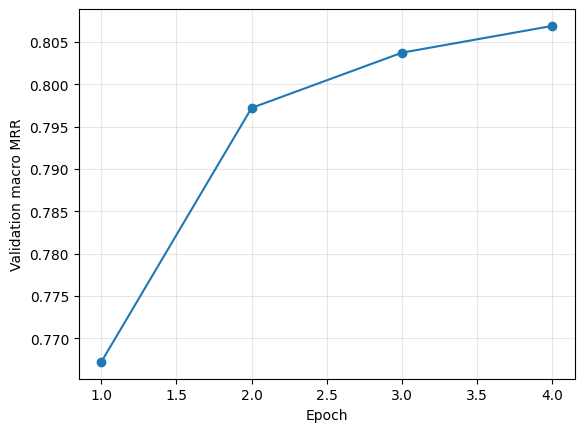

In [24]:
log = pd.DataFrame(training_log)
plt.plot(log.epoch, log.validation_mrr, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Validation macro MRR')
plt.grid(alpha=0.3)
plt.show()

## Notes

Mediomatix contains educational material, so these scores do not establish transfer to other domains. Low character overlap is a diagnostic, not proof of semantic understanding. This run does not compare cleaned and noisy training data.